# Exploring Segmented Regression For Cyclist Volume in Greater Adelaide

This model trials segmentation of it's parklands, CBD (inclusive of North Adelaide), and suburbs. This notebook aims to reveal any weak points in the data retrieved in graph_generation, finding more specific improvements for overall model capability.

## Segment distinction

__CBD__ - Falls within OSM Relation *R3093825*, with Mesh Block Population > 0 (PD_MB > 0)

__PARKLANDS__ - Falls within OSM Relation *R3093825* with Mesh Block Population 0

__SUBURBS__ - Falls outside OSM Relation *R3093825*

__SUBURBS_PARK__ - Falls outside OSM Relation *R3093825* with Mesh Block Population 0

Red lines below indicate mesh blocks. It is visible that the parklands surrounding the CBD have no buildings thus no population (excluding the homeless)
![CBD mesh blocks.png](<attachment:CBD mesh blocks.png>)
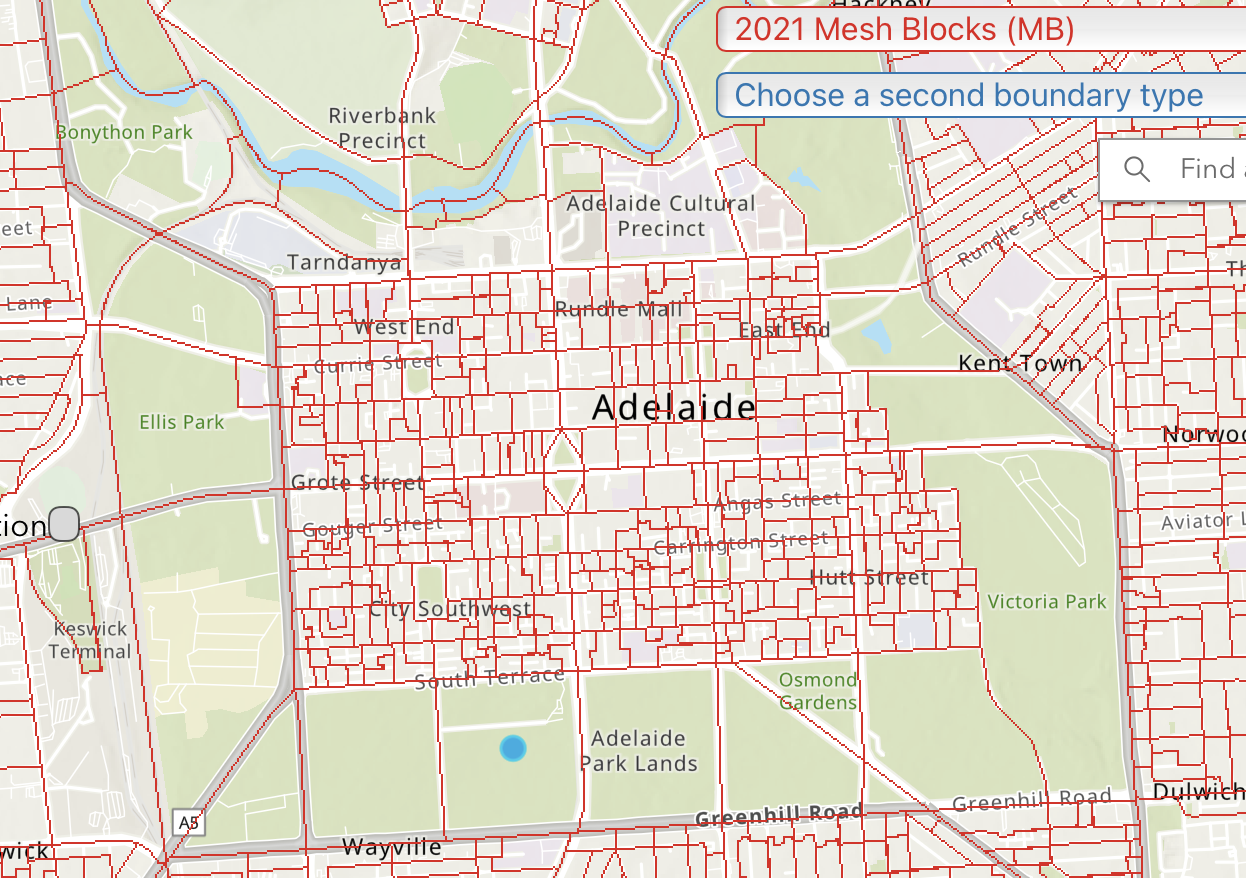

# Variables
- POW_CTW: N people who work in this DZN and cycle to work
- POW_FE: N people who work in this DZN and are fully engaged in employment or study
- PD_MB: MB population density
- DNL_DZN: Distance to nearest large DZN
- M_30_40, F_15_25: Age demographics, try males 30-40 and females 15-25 (best from Dadshova's)
- H_3500: Households with a THI of > 3500, place of enumeration, MB
- INF_CR: Listed cycle routes

__Monash Bicycle Infrastructure Classification__ - Binary dummy variables for every type of bicycle infrastructure

- MBI_BP: Dedicated bike path, Shared bike path
- MBI_PP: Pedestrian path/street with cycling allowed
- MBI_PTL: Painted bike lane, Painted bike lane (single-side)
- MBI_Sh: Sharrow
- MBI_SZ: Shared zone
- MBI_Bus: Bus lane with cycling allowed
- MBI_Mx: Mixed traffic

In [1]:
import osmnx as ox
import pandas as pd
import numpy as np
import geopandas as gpd
import networkx as nx
from scipy.spatial import cKDTree

graphml_path = "./../../graph_generation/graph_cache/graph_loaded.graphml"
G = ox.load_graphml(filepath=graphml_path)
print(f"Loaded graph: {len(G.nodes)} nodes, {len(G.edges)} edges")

Loaded graph: 466150 nodes, 893094 edges


# Constructing regression matrices

__*Pull count data*__

In [11]:
import pandas as pd

counts_path = "./../../all-data/super-tuesday-normalised/counts-2026.csv"

required_cols = ["total-count", "x", "y"]

REGRESSION_TABLE = pd.read_csv(counts_path)

missing = [col for col in required_cols if col not in REGRESSION_TABLE.columns]
if missing:
    raise ValueError(f"Missing required count columns: {missing}")

REGRESSION_TABLE = REGRESSION_TABLE[required_cols].copy()
REGRESSION_TABLE = REGRESSION_TABLE.rename(columns={"total-count": "COUNT"})
REGRESSION_TABLE["COUNT"] = pd.to_numeric(REGRESSION_TABLE["COUNT"], errors="coerce")
REGRESSION_TABLE["x"] = pd.to_numeric(REGRESSION_TABLE["x"], errors="coerce")
REGRESSION_TABLE["y"] = pd.to_numeric(REGRESSION_TABLE["y"], errors="coerce")

REGRESSION_TABLE = REGRESSION_TABLE.dropna(subset=["COUNT", "x", "y"]).reset_index(drop=True)

print(REGRESSION_TABLE.head())
print(f"Rows loaded: {len(REGRESSION_TABLE)}")

   COUNT           x          y
0   49.0  138.588749 -34.899506
1   53.0  138.589951 -34.902941
2   93.0  138.599362 -34.902090
3   82.0  138.595016 -34.903023
4   44.0  138.611103 -34.903433
Rows loaded: 130


__*Remove Out of Boundary Entries*__

In [12]:
# Monkey patch osmnx settings so I can use geocode to gdf
import osmnx as ox
import osmnx.settings as ox_settings
if not hasattr(ox_settings, 'http_user_agent'):
    ox_settings.http_user_agent = ox_settings.default_user_agent
if not hasattr(ox_settings, 'http_referer'):
    ox_settings.http_referer = ox_settings.default_referer
if not hasattr(ox_settings, 'nominatim_url'):
    ox_settings.nominatim_url = ox_settings.nominatim_endpoint
if not hasattr(ox_settings, 'http_accept_language'):
    ox_settings.http_accept_language = ox_settings.default_accept_language


In [13]:
import geopandas as gpd

# NOTE: this needs osmnx 1.x (see scripts/requirements.txt). osmnx 2.1.1 is
# internally inconsistent for geocode_to_gdf (its _nominatim.py reads settings
# that its settings.py no longer defines), so do not patch it per-setting.

cbd_boundary = ox.geocode_to_gdf("R3093825", by_osmid=True)  # Central Adelaide LGA, incl. North Adelaide
cbd_polygon = cbd_boundary.geometry.iloc[0]

count_points_all = gpd.GeoDataFrame(
    REGRESSION_TABLE.copy(),
    geometry=gpd.points_from_xy(REGRESSION_TABLE["x"], REGRESSION_TABLE["y"]),
    crs="EPSG:4326",
)
in_cbd = count_points_all.within(cbd_polygon.buffer(0)).to_numpy()

print(f"Count rows before trim: {len(REGRESSION_TABLE)}")
print(f"Outside boundary (-> SUBURBS): {int((~in_cbd).sum())}")
# Keep ALL rows: outside-boundary rows become the SUBURBS segment, not dropped.
REGRESSION_TABLE["IN_BOUNDARY"] = in_cbd
print(f"Count rows kept (all):  {len(REGRESSION_TABLE)}")

Count rows before trim: 130
Outside boundary (-> SUBURBS): 95
Count rows kept (all):  130


__*Join graph attributes from nearest edge*__

In [14]:
import numpy as np
from scipy.spatial import cKDTree

# Physical edges, deduplicated (both directions of two-way streets share tags)
nodes_gdf, edges_gdf = ox.graph_to_gdfs(G, nodes=True, edges=True)
edges_gdf = edges_gdf.reset_index()
edges_gdf["_u_v"] = [tuple(sorted((u, v))) for u, v in zip(edges_gdf["u"], edges_gdf["v"])]
edges_phys = edges_gdf.drop_duplicates(subset=["_u_v", "key"]).reset_index(drop=True)

metric_crs = edges_phys.estimate_utm_crs()
edges_metric = edges_phys.to_crs(metric_crs)
edge_midpoints = edges_metric.geometry.interpolate(0.5, normalized=True)
edge_tree = cKDTree(np.column_stack([edge_midpoints.x.values, edge_midpoints.y.values]))

count_points = gpd.GeoDataFrame(
    REGRESSION_TABLE.copy(),
    geometry=gpd.points_from_xy(REGRESSION_TABLE["x"], REGRESSION_TABLE["y"]),
    crs="EPSG:4326",
).to_crs(metric_crs)
count_coords = np.column_stack([count_points.geometry.x.values, count_points.geometry.y.values])

distances, indices = edge_tree.query(count_coords, k=1)
REGRESSION_TABLE["dist_to_edge"] = distances / 1000  # km
REGRESSION_TABLE["nearest_edge_idx"] = indices

edge_attr_cols = [
    "INF_CR", "MBI_BP", "MBI_PP", "MBI_PTL", "MBI_Sh", "MBI_SZ", "MBI_Bus", "MBI_Mx",
    "DNL_DZN", "PD_MB", "POW_CTW", "POW_FE", "M_30_40", "F_15_25", "H_3500",
]
for col in edge_attr_cols:
    if col in edges_phys.columns:
        REGRESSION_TABLE[col] = edges_phys.iloc[indices][col].values
    else:
        print(f"Warning: {col} not found in edges; filled with 0")
        REGRESSION_TABLE[col] = 0

print(f"Joined attributes. Shape: {REGRESSION_TABLE.shape}")

Joined attributes. Shape: (130, 21)


__*Prepare design matrices X_CBD and X_PARKLANDS*__

In [15]:
import numpy as np
import statsmodels.api as sm

MBI_COLS = ["MBI_BP", "MBI_PP", "MBI_PTL", "MBI_Sh", "MBI_SZ", "MBI_Bus"]  # MBI_Mx = reference

# Segment split: parklands = mesh blocks with zero population, CBD = populated
# Segment split. Inside boundary: PD_MB == 0 -> PARKLANDS, else CBD.
# Outside boundary -> SUBURBS. Coerce to numeric first (GraphML stores text).
pd_mb = pd.to_numeric(REGRESSION_TABLE["PD_MB"], errors="coerce").fillna(0)
REGRESSION_TABLE["SEGMENT"] = np.where(
    REGRESSION_TABLE["IN_BOUNDARY"],
    np.where(pd_mb == 0, "PARKLANDS", "CBD"),
    np.where(pd_mb == 0, "SUBURBS_PARKS", "SUBURBS"),
)
print(REGRESSION_TABLE["SEGMENT"].value_counts())

CBD_PREDICTORS = ["POW_CTW", "POW_FE", "M_30_40", "F_15_25", "H_3500",
                  "DNL_DZN", "PD_MB", "INF_CR"] + MBI_COLS
PARK_PREDICTORS = ["POW_CTW", "POW_FE", "M_30_40", "F_15_25", "H_3500",
                   "DNL_DZN", "INF_CR"] + MBI_COLS

def build_design(segment_name, predictors):
    seg = REGRESSION_TABLE.loc[REGRESSION_TABLE["SEGMENT"] == segment_name]
    cols = [c for c in predictors if c in seg.columns]
    data = seg[["COUNT"] + cols].dropna()
    # drop zero-variance predictors
    cols = [c for c in cols if data[c].nunique() > 1]
    data = data[["COUNT"] + cols]
    y = data["COUNT"]
    X = sm.add_constant(data[cols], has_constant="add")
    return X, y, cols

X_CBD, y_CBD, CBD_COLS = build_design("CBD", CBD_PREDICTORS)
X_SUBURBS, y_SUBURBS, SUB_COLS = build_design("SUBURBS", CBD_PREDICTORS)  # full set, per user choice
X_SUBURBS_PARKS, y_SUBURBS_PARKS, SUBPARK_COLS = build_design("SUBURBS_PARKS", PARK_PREDICTORS)
X_PARKLANDS, y_PARKLANDS, PARK_COLS = build_design("PARKLANDS", PARK_PREDICTORS)

print(f"X_CBD: {X_CBD.shape}, y mean {y_CBD.mean():.2f}, var {y_CBD.var():.2f}")
print(f"X_PARKLANDS: {X_PARKLANDS.shape}, y mean {y_PARKLANDS.mean():.2f}, var {y_PARKLANDS.var():.2f}")
print(f"X_SUBURBS: {X_SUBURBS.shape}, y mean {y_SUBURBS.mean():.2f}, var {y_SUBURBS.var():.2f}")
print(f"X_SUBURBS_PARKS: {X_SUBURBS_PARKS.shape}, y mean {y_SUBURBS_PARKS.mean():.2f}, var {y_SUBURBS_PARKS.var():.2f}")

SEGMENT
SUBURBS          70
SUBURBS_PARKS    25
PARKLANDS        20
CBD              15
Name: count, dtype: int64
X_CBD: (15, 11), y mean 216.00, var 14605.43
X_PARKLANDS: (20, 9), y mean 168.95, var 8392.05
X_SUBURBS: (70, 12), y mean 68.37, var 4236.53
X_SUBURBS_PARKS: (25, 8), y mean 81.28, var 8958.63


In [20]:
# Correlation matrix of predictors (plus COUNT) for each segment.
# Use this to spot collinear predictors before reading the fits.
import pandas as pd

segment_designs = {
    "CBD": (X_CBD, y_CBD),
    "PARKLANDS": (X_PARKLANDS, y_PARKLANDS),
    "SUBURBS": (X_SUBURBS, y_SUBURBS),
    "SUBURBS_PARKS": (X_SUBURBS_PARKS, y_SUBURBS_PARKS),
}

pd.set_option("display.width", 200)
for name, (X_seg, y_seg) in segment_designs.items():
    # Drop the constant column; it has no correlation and would be NaN.
    data = X_seg.drop(columns="const", errors="ignore").copy()
    data["COUNT"] = y_seg.values
    print(f"=== {name} (n={len(data)}) ===")
    if data.shape[1] < 2:
        print("  not enough columns for a correlation matrix")
        continue
    corr = data.corr().round(2)
    print(corr.to_string())
    print()


=== CBD (n=15) ===
         POW_CTW  POW_FE  M_30_40  F_15_25  H_3500  DNL_DZN  PD_MB  INF_CR  MBI_BP  MBI_PTL  COUNT
POW_CTW     1.00    0.94    -0.03     0.50   -0.50    -0.79   0.60   -0.31    0.12     0.60   0.18
POW_FE      0.94    1.00     0.10     0.42   -0.48    -0.72   0.56   -0.41   -0.01     0.49   0.06
M_30_40    -0.03    0.10     1.00    -0.09    0.47     0.21   0.07   -0.23   -0.34     0.26  -0.62
F_15_25     0.50    0.42    -0.09     1.00   -0.10    -0.36   0.95   -0.12    0.63    -0.14  -0.33
H_3500     -0.50   -0.48     0.47    -0.10    1.00     0.74  -0.06   -0.11   -0.17    -0.14  -0.49
DNL_DZN    -0.79   -0.72     0.21    -0.36    0.74     1.00  -0.36    0.30   -0.03    -0.38  -0.24
PD_MB       0.60    0.56     0.07     0.95   -0.06    -0.36   1.00   -0.16    0.56     0.01  -0.35
INF_CR     -0.31   -0.41    -0.23    -0.12   -0.11     0.30  -0.16    1.00    0.68    -0.13   0.23
MBI_BP      0.12   -0.01    -0.34     0.63   -0.17    -0.03   0.56    0.68    1.00    -0.2

__*Export Matrices*__

In [16]:
export_cbd = X_CBD.copy()
export_cbd["COUNT"] = y_CBD.values
export_cbd.to_csv("./model_3_X_y_CBD.csv", index=False)

export_park = X_PARKLANDS.copy()
export_park["COUNT"] = y_PARKLANDS.values
export_park.to_csv("./model_3_X_y_PARKLANDS.csv", index=False)

export_sub = X_SUBURBS.copy()
export_sub["COUNT"] = y_SUBURBS.values
export_sub.to_csv("./model_3_X_y_SUBURBS.csv", index=False)

export_subpark = X_SUBURBS_PARKS.copy()
export_subpark["COUNT"] = y_SUBURBS_PARKS.values
export_subpark.to_csv("./model_3_X_y_SUBURBS_PARKS.csv", index=False)

print(f"Exported CBD: {export_cbd.shape}; PARKLANDS: {export_park.shape}; SUBURBS: {export_sub.shape}; SUBURBS_PARKS: {export_subpark.shape}")

Exported CBD: (15, 12); PARKLANDS: (20, 10); SUBURBS: (70, 13); SUBURBS_PARKS: (25, 9)


# Fit linear models

In [53]:
def fit_ols(y, X, label):
    model = sm.OLS(y, X).fit(maxiter=500, disp=False)
    print(f"=== {label} ===")
    print(model.summary())
    return model

ols_CBD = fit_ols(y_CBD, X_CBD, "CBD")
ols_PARKLANDS = fit_ols(y_PARKLANDS, X_PARKLANDS, "PARKLANDS")
ols_SUBURBS = fit_ols(y_SUBURBS, X_SUBURBS, "SUBURBS")
ols_SUBURBS_PARKS = fit_ols(y_SUBURBS_PARKS, X_SUBURBS_PARKS, "SUBURBS_PARKS")


=== CBD ===
                            OLS Regression Results                            
Dep. Variable:                  COUNT   R-squared:                       0.791
Model:                            OLS   Adj. R-squared:                  0.268
Method:                 Least Squares   F-statistic:                     1.514
Date:                Fri, 06 Nov 2026   Prob (F-statistic):              0.367
Time:                        11:33:19   Log-Likelihood:                -80.946
No. Observations:                  15   AIC:                             183.9
Df Residuals:                       4   BIC:                             191.7
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        186.6919    159.920      1.

# Fit Poisson Models

In [ ]:
def fit_poisson(y, X, label):
    model = sm.Poisson(y, X).fit(maxiter=500, disp=False)
    print(f"=== {label} ===")
    print(model.summary())
    return model

pois_CBD = fit_poisson(y_CBD, X_CBD, "CBD")
pois_PARKLANDS = fit_poisson(y_PARKLANDS, X_PARKLANDS, "PARKLANDS")
pois_SUBURBS = fit_poisson(y_SUBURBS, X_SUBURBS, "SUBURBS")
pois_SUBURBS_PARKS = fit_poisson(y_SUBURBS_PARKS, X_SUBURBS_PARKS, "SUBURBS_PARKS")

=== CBD ===
                          Poisson Regression Results                          
Dep. Variable:                  COUNT   No. Observations:                   15
Model:                        Poisson   Df Residuals:                        4
Method:                           MLE   Df Model:                           10
Date:                Thu, 05 Nov 2026   Pseudo R-squ.:                     nan
Time:                        18:38:50   Log-Likelihood:                    nan
converged:                       True   LL-Null:                       -566.20
Covariance Type:            nonrobust   LLR p-value:                       nan
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const             nan        nan        nan        nan         nan         nan
POW_CTW           nan        nan        nan        nan         nan         nan
POW_FE            nan        nan        

/opt/anaconda3/envs/CyclistVolumeModelling/lib/python3.12/site-packages/statsmodels/discrete/discrete_model.py:1149: RuntimeWarning: overflow encountered in exp
  return np.exp(linpred)
/opt/anaconda3/envs/CyclistVolumeModelling/lib/python3.12/site-packages/statsmodels/discrete/discrete_model.py:1708: RuntimeWarning: overflow encountered in exp
  L = np.exp(np.dot(X, params) + exposure + offset)
/opt/anaconda3/envs/CyclistVolumeModelling/lib/python3.12/site-packages/statsmodels/discrete/discrete_model.py:1709: RuntimeWarning: invalid value encountered in multiply
  return -np.dot(L * X.T, X)
/opt/anaconda3/envs/CyclistVolumeModelling/lib/python3.12/site-packages/statsmodels/discrete/discrete_model.py:1619: RuntimeWarning: overflow encountered in exp
  L = np.exp(np.dot(X, params) + offset + exposure)


# Column Holdout testing

In [51]:
# Change around to test different
target_segment = "SUBURBS"
target_cols = ["MBI_PTL", "MBI_Sh"]

In [52]:
def fit_ols_holdout(segment, target_cols):
    """Fit OLS for `segment` with and without `target_cols`, return both models."""
    designs = {
        "CBD": (y_CBD, X_CBD),
        "PARKLANDS": (y_PARKLANDS, X_PARKLANDS),
        "SUBURBS": (y_SUBURBS, X_SUBURBS),
        "SUBURBS_PARKS": (y_SUBURBS_PARKS, X_SUBURBS_PARKS),
    }
    y, X = designs[segment]

    missing = [col for col in target_cols if col not in X.columns]
    if missing:
        raise ValueError(f"{missing} not predictors in {segment}: {list(X.columns)}")

    X_without = X.drop(columns=target_cols)
    label_suffix = "_".join(target_cols)

    model_full = fit_ols(y, X, f"{segment}_full")
    model_drop = fit_ols(y, X_without, f"{segment}_without_{label_suffix}")
    return model_full, model_drop

ols_full, ols_dropped = fit_ols_holdout(target_segment, target_cols)


=== SUBURBS_full ===
                            OLS Regression Results                            
Dep. Variable:                  COUNT   R-squared:                       0.554
Model:                            OLS   Adj. R-squared:                  0.469
Method:                 Least Squares   F-statistic:                     6.548
Date:                Fri, 06 Nov 2026   Prob (F-statistic):           5.88e-07
Time:                        11:32:56   Log-Likelihood:                -362.87
No. Observations:                  70   AIC:                             749.7
Df Residuals:                      58   BIC:                             776.7
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         81.8477     19.86